# Lab 03 — Pretraining the Base Model
### From next-token likelihood to a reproducible training run

**Language:** English · **Study time:** two sessions of 90 minutes · **Default device:** CPU

In Lab 1 you prepared input–target pairs. In Lab 2 you built a Transformer. Here you will update its parameters, measure learning on held-out documents, and recover a run from a checkpoint.

This independently authored lab follows **Step 3** of FareedKhan-dev's repository. Its teaching approach draws on Stanford CS336's emphasis on constructing language-model systems and checking their behavior. It is not an official Stanford assignment. The reference training loop runs from top to bottom before you attempt the independent exercises.

**What you will produce**
- A small pretrained causal Transformer and a JSON configuration.
- Token-weighted train/validation loss and perplexity measurements.
- Learning-rate and loss curves, plus training metrics in JSON.
- Interruption and final checkpoints containing optimizer and random-number-generator state.
- A numerical test that the next update is reproduced after a checkpoint reload.

**Sources and scope**
- [Repository Step 3](https://github.com/FareedKhan-dev/train-llm-from-scratch#step-3-pretraining-the-base-model)
- [Simple trainer](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/scripts/train_transformer.py)
- [Scalable trainer](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/scripts/pretrain_base.py)
- [Optimizer builder](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/optim/__init__.py) and [schedules](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/optim/schedules.py)
- [Modern optimizer notes](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/docs/modern/optimizers.md)
- [Stanford CS336, Spring 2025](https://cs336.stanford.edu/spring2025/) and [Assignment 1](https://github.com/stanford-cs336/assignment1-basics)

Sources were inspected on 14 November 2026. README blob SHA: `ce303f30752c6ddc85be2dcbccc12ed6b3d4efdf`. Scalable-trainer blob SHA: `4ea33c07dd1e979e80dc0e57732da241f1590183`.

The practical run uses the classic model from Lab 2, a small English corpus, AdamW, and cosine warmup/decay. Repository extensions—presets, step decay, mixed precision, activation checkpointing, DDP, Muon, and WSD—are covered in the later sections. GPU and distributed recipes require their corresponding hardware.


### Verified reference run

The saved outputs come from an executed CPU run using PyTorch 2.15.0+cpu, seed 42, and the default configuration. All 16 code cells completed, including gradient accumulation equivalence, checkpoint replay, and reference exercise checks.

| Metric | Before training | After 200 updates |
|---|---:|---:|
| Train loss, nats/token | 4.9893 | 1.1585 |
| Validation loss, nats/token | 4.9956 | 1.1499 |
| Validation perplexity | 147.77 | 3.16 |

The model has 34,433 parameters and processes 192 target tokens per update, for 38,400 target-token presentations in the recorded run. Repeated sampling can revisit tokens. Your numerical results may vary with software or hardware. Optional GPU, distributed, and repository command-line recipes were not executed in this reference run.


## 1. Set up a controlled experiment

Install dependencies into your notebook kernel with `%pip install torch matplotlib`, or use `python -m pip install torch matplotlib` in its environment. Restart the kernel if required. This notebook embeds its data and model definitions, so Lab 1 and Lab 2 files do not need to be executed first.

Run the CPU configuration first. All generated files go into a new run directory under `lab03_runs/`. Record versions and configuration with each run. A seed helps reproduce sampling and initialization within a compatible software/hardware environment.

| Setting | Meaning | Default |
|---|---|---|
| `micro_batch` | sequences in one forward/backward pass | 4 |
| `context_length` | predicted tokens per sequence | 24 |
| `grad_accum` | microbatches per optimizer update | 2 |
| `total_updates` | planned optimizer updates | 200 |
| `warmup_updates` | initial increasing-LR phase | 20 |
| `width`, `heads`, `layers` | model dimensions | 32, 4, 2 |

An **update** changes the weights once. A **microbatch** contributes a gradient. An **epoch** usually describes one traversal of a dataset; our random-window sampler is driven by an update budget instead.


In [1]:
import copy
import hashlib
import json
import math
import os
import random
import tempfile
import time
from contextlib import nullcontext
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

@dataclass
class TrainingConfig:
    seed: int = 42
    device: str = "cpu"
    micro_batch: int = 4
    context_length: int = 24
    grad_accum: int = 2
    total_updates: int = 200
    warmup_updates: int = 20
    peak_lr: float = 0.003
    min_lr: float = 0.0003
    weight_decay: float = 0.01
    grad_clip: float = 1.0
    width: int = 32
    heads: int = 4
    layers: int = 2
    eval_every: int = 20
    bf16: bool = False

cfg = TrainingConfig()
assert 0 < cfg.warmup_updates < cfg.total_updates
assert cfg.width % cfg.heads == 0
assert cfg.micro_batch > 0 and cfg.grad_accum > 0
random.seed(cfg.seed)
torch.manual_seed(cfg.seed)
torch.set_num_threads(1)
DEVICE = torch.device(cfg.device)
if DEVICE.type == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("CUDA was requested but is unavailable.")
if cfg.bf16 and (DEVICE.type != "cuda" or not torch.cuda.is_bf16_supported()):
    raise RuntimeError("The optional bf16 run requires a supported CUDA device.")

Path("lab03_runs").mkdir(exist_ok=True)
RUN_DIR = Path(tempfile.mkdtemp(prefix="run_", dir="lab03_runs"))
(RUN_DIR / "config.json").write_text(json.dumps(asdict(cfg), indent=2))
print("PyTorch:", torch.__version__, "| device:", DEVICE)
print("Output directory:", RUN_DIR)


PyTorch: 2.15.0+cpu | device: cpu
Output directory: /workspace/scratch/d20f4a09d498/lab03_runs/run_pvg4r57e


## 2. Build training and validation data

The corpus below contains short English sentences generated from a fixed grammar. Documents are unique and split before tokenization. Held-out documents reuse words and grammar, so validation measures generalization to combinations from this small distribution. It provides a tractable training demonstration; performance on this corpus cannot establish broad language ability.

We use ASCII character IDs 0–127 and reserve 128 for EOT. This fixed vocabulary has 129 entries and is completely specified before seeing either split. Using a different tokenizer changes the meaning and scale of token-level loss. In a larger run, reuse the exact tokenizer that produced the training IDs.

Append one EOT per document, concatenate within each split, and sample windows of length `T+1`. Inputs use the first `T` tokens and targets use the last `T`. A separate sampler generator allows checkpointing the next training draw. Evaluation will use fixed windows and never advance this generator.


In [2]:
names = ["Anna", "Ben", "Clara", "David", "Emma", "Finn", "Grace", "Henry"]
places = ["park", "garden", "school", "market", "library"]
actions = ["read a book", "watched a bird", "found a flower", "shared a story"]
documents = [f"{name} went to the {place} and {action}." for name in names for place in places for action in actions]
assert len(documents) == len(set(documents)) == 160
random.Random(cfg.seed).shuffle(documents)
train_documents, val_documents = documents[:128], documents[128:]
assert set(train_documents).isdisjoint(val_documents)
EOT_ID, VOCAB_SIZE = 128, 129

def encode_documents(documents):
    result = []
    for document in documents:
        assert document.isascii()
        result.extend(ord(character) for character in document)
        result.append(EOT_ID)
    return torch.tensor(result, dtype=torch.long)

train_tokens = encode_documents(train_documents)
val_tokens = encode_documents(val_documents)
corpus_hash = hashlib.sha256(json.dumps([train_documents, val_documents]).encode()).hexdigest()
tokenizer_spec = {"kind": "ascii-character", "vocab_size": VOCAB_SIZE, "eot_id": EOT_ID}
(RUN_DIR / "data_manifest.json").write_text(json.dumps({"tokenizer": tokenizer_spec, "corpus_sha256": corpus_hash}, indent=2))

def sample_batch(tokens, generator, batch_size, context_length):
    if len(tokens) <= context_length:
        raise ValueError("The stream must contain at least T+1 tokens.")
    starts = torch.randint(len(tokens) - context_length, (batch_size,), generator=generator)
    windows = torch.stack([tokens[int(start):int(start) + context_length + 1] for start in starts])
    return windows[:, :-1].to(DEVICE), windows[:, 1:].to(DEVICE)

sampler = torch.Generator().manual_seed(cfg.seed + 1)
preview_generator = torch.Generator().manual_seed(0)
preview_x, preview_y = sample_batch(train_tokens, preview_generator, cfg.micro_batch, cfg.context_length)
assert torch.equal(preview_x[:, 1:], preview_y[:, :-1])
print("Documents:", len(train_documents), "train /", len(val_documents), "validation")
print("Tokens:", len(train_tokens), "train /", len(val_tokens), "validation")
print("Batch shape:", tuple(preview_x.shape))


Documents: 128 train / 32 validation
Tokens: 5550 train / 1398 validation
Batch shape: (4, 24)


## 3. Reuse the model from Lab 2

The following cell contains the same classic-model definitions from your attached Lab 2. It preserves learned token/position embeddings, bias-free Q/K/V, ReLU MLPs, pre-norm blocks, and an untied output layer. Training code only needs `model(inputs, targets)` to return `(logits, loss)`.

| Interface | Shape |
|---|---|
| inputs / targets | `(B, T)` integers |
| logits | `(B, T, V)` |
| loss | scalar mean over `B*T` targets |

Before optimization, the causality test changes future input IDs and checks that earlier logits stay unchanged. A model that can see its future labels can obtain misleadingly low training loss.


In [3]:
class MLP(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.hidden = nn.Linear(width, 4 * width)
        self.proj = nn.Linear(4 * width, width)

    def forward(self, x):
        return self.proj(F.relu(self.hidden(x)))

def causal_attention(q, k, v):
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    length = q.shape[-2]
    allowed = torch.ones(length, length, dtype=torch.bool, device=q.device).tril()
    weights = scores.masked_fill(~allowed, float("-inf")).softmax(dim=-1)
    return weights @ v, weights

class Head(nn.Module):
    def __init__(self, width, head_width):
        super().__init__()
        self.query = nn.Linear(width, head_width, bias=False)
        self.key = nn.Linear(width, head_width, bias=False)
        self.value = nn.Linear(width, head_width, bias=False)

    def forward(self, x):
        output, _ = causal_attention(self.query(x), self.key(x), self.value(x))
        return output

class MultiHeadAttention(nn.Module):
    def __init__(self, width, heads):
        super().__init__()
        if width % heads:
            raise ValueError("Embedding width must be divisible by head count.")
        self.heads = nn.ModuleList([Head(width, width // heads) for _ in range(heads)])
        self.proj = nn.Linear(width, width)

    def forward(self, x):
        return self.proj(torch.cat([head(x) for head in self.heads], dim=-1))

class Block(nn.Module):
    def __init__(self, width, heads):
        super().__init__()
        self.ln1 = nn.LayerNorm(width)
        self.attn = MultiHeadAttention(width, heads)
        self.ln2 = nn.LayerNorm(width)
        self.mlp = MLP(width)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))

class Transformer(nn.Module):
    def __init__(self, vocab_size, width, heads, context_length, layers):
        super().__init__()
        self.context_length = context_length
        self.token_embed = nn.Embedding(vocab_size, width)
        self.position_embed = nn.Embedding(context_length, width)
        self.blocks = nn.ModuleList([Block(width, heads) for _ in range(layers)])
        self.norm = nn.LayerNorm(width)
        self.lm_head = nn.Linear(width, vocab_size)

    def forward_hidden(self, ids):
        length = ids.shape[1]
        if not 1 <= length <= self.context_length:
            raise ValueError("Sequence length is outside the supported context.")
        positions = torch.arange(length, device=ids.device)
        hidden = self.token_embed(ids) + self.position_embed(positions)
        for block in self.blocks:
            hidden = block(hidden)
        return self.norm(hidden)

    def forward(self, ids, targets=None):
        logits = self.lm_head(self.forward_hidden(ids))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1).long())
        return logits, loss


In [4]:
def new_model():
    return Transformer(VOCAB_SIZE, cfg.width, cfg.heads, cfg.context_length, cfg.layers).to(DEVICE)

model = new_model()
model.eval()
with torch.no_grad():
    original, _ = model(preview_x)
    changed = preview_x.clone()
    changed[:, 12:] = (changed[:, 12:] + 1) % VOCAB_SIZE
    perturbed, _ = model(changed)
assert torch.allclose(original[:, :12], perturbed[:, :12], atol=1e-6)
print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))


Parameters: 34433


## 4. Derive the training objective

For a document token sequence, autoregressive likelihood factors as

$$p_\theta(x_1,\ldots,x_n)=\prod_{t=1}^{n}p_\theta(x_t\mid x_{<t}).$$

Our finite windows optimize next-token predictions given the available window prefix. With `N=B*T` target positions, the empirical objective is

$$\mathcal L(\theta)=-\frac1N\sum_{i=1}^{N}\log p_\theta(y_i\mid\mathrm{context}_i).$$

For logits $z$, cross-entropy at one position is $\log\sum_v e^{z_v}-z_y$. Its derivative with respect to a logit is $p_v-\mathbf1[v=y]$. Backpropagation applies the chain rule to obtain gradients for every model parameter.

A uniform distribution has loss $\ln V$. Perplexity is $\exp(\mathcal L)$ when loss uses natural logarithms. It is the inverse geometric mean probability assigned to target tokens. Compare perplexity only with compatible tokenization and evaluation protocols.

**Worked example:** If target probabilities are 0.5 and 0.25, mean loss is approximately 1.0397 and perplexity is approximately 2.828. Average negative log-likelihood first, then exponentiate.

**Exercise 1:** Implement cross-entropy with `logsumexp` and `gather`. The optional exercise section contains a starter and checks.


In [5]:
example_probabilities = torch.tensor([0.5, 0.25])
example_loss = -example_probabilities.log().mean()
assert math.isclose(example_loss.exp().item(), math.sqrt(8), rel_tol=1e-6)
uniform_logits = torch.zeros(2, VOCAB_SIZE)
uniform_loss = F.cross_entropy(uniform_logits, torch.tensor([0, 1]))
assert math.isclose(uniform_loss.item(), math.log(VOCAB_SIZE), rel_tol=1e-6)
print(f"Uniform baseline: loss={uniform_loss.item():.4f}, perplexity={VOCAB_SIZE}")


Uniform baseline: loss=4.8598, perplexity=129


## 5. From gradients to AdamW updates

Gradient descent uses $\theta\leftarrow\theta-\eta g$, where $g=\nabla_\theta\mathcal L$. AdamW tracks first and second moments elementwise:

$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\qquad v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2.$$
$$\hat m_t=m_t/(1-\beta_1^t),\qquad\hat v_t=v_t/(1-\beta_2^t).$$
$$\theta_t=(1-\eta_t\lambda)\theta_{t-1}-\eta_t\hat m_t/(\sqrt{\hat v_t}+\epsilon).$$

The moment estimates make update scales depend on gradient history. Decoupled weight decay shrinks parameters directly. Following the repository's scalable optimizer builder, this lab applies weight decay to parameters with at least two dimensions and excludes biases and normalization scales. The simpler repository trainer passes all parameters directly to AdamW.

`zero_grad(set_to_none=True)` clears previous gradients. `backward()` accumulates gradients. `optimizer.step()` changes parameters and optimizer state. Learning rate, moments, and weight decay together determine the update.


In [6]:
def make_optimizer(model):
    decay = [p for p in model.parameters() if p.requires_grad and p.ndim >= 2]
    no_decay = [p for p in model.parameters() if p.requires_grad and p.ndim < 2]
    groups = [{"params": decay, "weight_decay": cfg.weight_decay},
              {"params": no_decay, "weight_decay": 0.0}]
    assert len({id(p) for group in groups for p in group["params"]}) == len(list(model.parameters()))
    return torch.optim.AdamW(groups, lr=cfg.peak_lr, betas=(0.9, 0.95))

optimizer = make_optimizer(model)
print("Decayed parameter tensors:", len(optimizer.param_groups[0]["params"]))
print("Non-decayed parameter tensors:", len(optimizer.param_groups[1]["params"]))


Decayed parameter tensors: 33
Non-decayed parameter tensors: 17


## 6. Schedule the learning rate

The simple repository trainer uses one step decay, typically a 10× drop near 80% of the run. The scalable trainer offers warmup followed by cosine, linear, or warmup-stable-decay (WSD) schedules.

We use the scalable trainer's zero-based convention: at update index `s=0`, warmup starts at `peak_lr / warmup_updates`. After warmup,

$$\eta(s)=\eta_{min}+\tfrac12(\eta_{max}-\eta_{min})[1+\cos(\pi p)],\quad p=\frac{s-W}{S-W}.$$

Here $W$ is warmup length and $S$ is the total update budget. The final executed index is $S-1$; the formula reaches the floor at index $S$. A checkpoint records the original schedule configuration so resume continues at the correct index.

**Exercise 2:** Calculate the first LR for a peak of 0.003 and 20 warmup updates. Then implement the cosine function independently and check both boundaries.


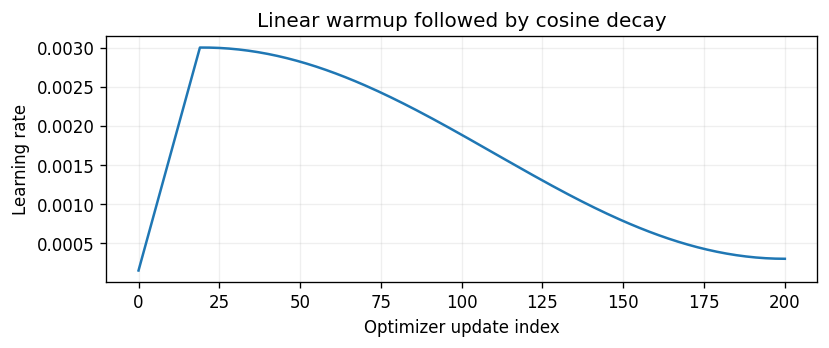

In [7]:
def learning_rate(step):
    if step < cfg.warmup_updates:
        return cfg.peak_lr * (step + 1) / cfg.warmup_updates
    if step >= cfg.total_updates:
        return cfg.min_lr
    progress = (step - cfg.warmup_updates) / (cfg.total_updates - cfg.warmup_updates)
    return cfg.min_lr + 0.5 * (cfg.peak_lr - cfg.min_lr) * (1 + math.cos(math.pi * progress))

assert math.isclose(learning_rate(0), 0.00015)
assert math.isclose(learning_rate(cfg.warmup_updates), cfg.peak_lr)
assert math.isclose(learning_rate(cfg.total_updates), cfg.min_lr)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(cfg.total_updates + 1), [learning_rate(s) for s in range(cfg.total_updates + 1)])
ax.set(xlabel="Optimizer update index", ylabel="Learning rate", title="Linear warmup followed by cosine decay")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RUN_DIR / "learning_rate.png", dpi=140)
plt.show()


## 7. Accumulate gradients and clip their norm

For $K$ equal-sized microbatches, the full-batch mean loss is $\mathcal L=\frac1K\sum_k\mathcal L_k$. Linearity of differentiation gives

$$\nabla\mathcal L=\sum_k\nabla(\mathcal L_k/K).$$

Divide each microbatch loss by `K`, call `backward()` for each, then take one optimizer step. Clear gradients once before the microbatch loop. For unequal numbers of valid tokens, use token-count weights instead of dividing equally by `K`.

With $D$ DDP workers, effective batch size is $B_{micro}KD$ sequences and the number of predicted tokens per update is $B_{micro}KDT$. Increasing accumulation permits a larger effective batch without simultaneously retaining every microbatch's activations.

Global norm clipping transforms $g$ into $g\min(1,c/\|g\|_2)$. Apply it after accumulation. The returned norm is measured **before** clipping. If FP16 gradient scaling is used, unscale before clipping.

**Numerical test:** Compare gradients from one concatenated batch with gradients from two microbatches. Our model has no dropout or batch-dependent normalization, so FP32 gradients should agree within numerical tolerance.


In [8]:
full_model = copy.deepcopy(model)
accum_model = copy.deepcopy(model)
check_generator = torch.Generator().manual_seed(123)
big_x, big_y = sample_batch(train_tokens, check_generator, cfg.micro_batch * cfg.grad_accum, cfg.context_length)
full_model.zero_grad(set_to_none=True)
_, full_loss = full_model(big_x, big_y)
full_loss.backward()
accum_model.zero_grad(set_to_none=True)
for micro_x, micro_y in zip(big_x.chunk(cfg.grad_accum), big_y.chunk(cfg.grad_accum)):
    _, micro_loss = accum_model(micro_x, micro_y)
    (micro_loss / cfg.grad_accum).backward()
for full_parameter, accum_parameter in zip(full_model.parameters(), accum_model.parameters()):
    assert torch.allclose(full_parameter.grad, accum_parameter.grad, atol=2e-6, rtol=2e-4)
del full_model, accum_model
print("Accumulated gradients agree with the full-batch mean gradient.")
print("Effective sequences/update:", cfg.micro_batch * cfg.grad_accum)
print("Predicted tokens/update:", cfg.micro_batch * cfg.grad_accum * cfg.context_length)


Accumulated gradients agree with the full-batch mean gradient.
Effective sequences/update: 8
Predicted tokens/update: 192


## 8. Evaluate without changing the training experiment

`eval()` changes training-specific module behavior; `no_grad()` disables graph construction. They serve different purposes. Our evaluator uses both, then restores the model's original mode.

Evaluate fixed, non-overlapping input windows from each split. Sum negative log-likelihood and divide by the number of target tokens, so a smaller final batch receives the correct weight. The fixed suite excludes the incomplete tail shorter than a full context window. Its coverage is printed below.

Evaluation uses no random sampling, so it leaves the training sampler untouched. It runs in FP32 for consistent monitoring even if training later uses bf16. A fixed validation suite makes checkpoints comparable; repeated hyperparameter tuning still requires an additional independent test set for a final generalization claim.


In [9]:
def evaluation_batches(tokens):
    starts = list(range(0, len(tokens) - cfg.context_length, cfg.context_length))
    for offset in range(0, len(starts), 32):
        selected = starts[offset:offset + 32]
        windows = torch.stack([tokens[start:start + cfg.context_length + 1] for start in selected])
        yield windows[:, :-1].to(DEVICE), windows[:, 1:].to(DEVICE)

@torch.no_grad()
def evaluate(model, tokens):
    was_training = model.training
    total_nll, total_tokens = 0.0, 0
    model.eval()
    try:
        for x, y in evaluation_batches(tokens):
            logits, _ = model(x)
            total_nll += F.cross_entropy(logits.reshape(-1, VOCAB_SIZE), y.reshape(-1), reduction="sum").item()
            total_tokens += y.numel()
    finally:
        model.train(was_training)
    if total_tokens == 0:
        raise ValueError("No complete evaluation windows.")
    mean_loss = total_nll / total_tokens
    return {"loss": mean_loss, "perplexity": math.exp(mean_loss), "tokens": total_tokens}

sampler_before = sampler.get_state().clone()
initial_train = evaluate(model, train_tokens)
initial_val = evaluate(model, val_tokens)
assert torch.equal(sampler.get_state(), sampler_before)
print("Initial train:", initial_train)
print("Initial validation:", initial_val)


Initial train: {'loss': 4.9892698015485495, 'perplexity': 146.8291699097633, 'tokens': 5544}
Initial validation: {'loss': 4.995645808077406, 'perplexity': 147.76834456588142, 'tokens': 1392}


## 9. Implement one optimizer update

The order below follows the scalable repository loop: set LR, clear gradients, process microbatches, backpropagate scaled mean losses, clip, then update weights. The lab adds explicit finite-value checks for easier debugging.

By default, `autocast_context()` is a no-op. Setting `device="cuda"` and `bf16=True` in the configuration enables the optional supported CUDA path. The CPU experiment uses FP32.

A finite gradient does not imply that the learning rate is appropriate. Inspect loss and gradient norms across multiple updates. The optimizer's adaptive transformation also means clipping gradients does not directly cap the parameter-update norm at the clipping threshold.


In [10]:
def autocast_context():
    if cfg.bf16:
        return torch.autocast(device_type="cuda", dtype=torch.bfloat16)
    return nullcontext()

def train_update(model, optimizer, generator, step):
    model.train()
    lr = learning_rate(step)
    for group in optimizer.param_groups:
        group["lr"] = lr
    optimizer.zero_grad(set_to_none=True)
    mean_loss = 0.0
    for _ in range(cfg.grad_accum):
        x, y = sample_batch(train_tokens, generator, cfg.micro_batch, cfg.context_length)
        with autocast_context():
            _, loss = model(x, y)
        if not torch.isfinite(loss):
            raise FloatingPointError("Non-finite training loss.")
        mean_loss += loss.detach().item() / cfg.grad_accum
        (loss / cfg.grad_accum).backward()
    grad_norm = nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip, error_if_nonfinite=True)
    optimizer.step()
    return {"update": step + 1, "loss": mean_loss, "lr": lr, "grad_norm": float(grad_norm)}

def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)

history = {"updates": [], "evaluation": [{"completed_updates": 0, "train": initial_train, "validation": initial_val}]}

def fit(model, optimizer, generator, start_update, stop_update, history):
    for step in range(start_update, stop_update):
        synchronize()
        start = time.perf_counter()
        record = train_update(model, optimizer, generator, step)
        synchronize()
        seconds = time.perf_counter() - start
        record["tokens_per_second"] = cfg.micro_batch * cfg.grad_accum * cfg.context_length / seconds
        history["updates"].append(record)
        completed = step + 1
        if completed % cfg.eval_every == 0 or completed == stop_update:
            train_metrics = evaluate(model, train_tokens)
            val_metrics = evaluate(model, val_tokens)
            history["evaluation"].append({"completed_updates": completed, "train": train_metrics, "validation": val_metrics})
            print(f"update={completed:3d} train={train_metrics['loss']:.3f} val={val_metrics['loss']:.3f} "
                  f"lr={record['lr']:.6f} grad_norm={record['grad_norm']:.3f} tok/s={record['tokens_per_second']:.0f}")

interruption_point = cfg.total_updates // 2
if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats(DEVICE)
fit(model, optimizer, sampler, 0, interruption_point, history)


update= 20 train=3.459 val=3.470 lr=0.003000 grad_norm=1.023 tok/s=23115
update= 40 train=2.353 val=2.353 lr=0.002926 grad_norm=0.505 tok/s=25785
update= 60 train=1.940 val=1.923 lr=0.002699 grad_norm=0.505 tok/s=25606
update= 80 train=1.674 val=1.674 lr=0.002345 grad_norm=0.448 tok/s=26663
update=100 train=1.495 val=1.475 lr=0.001908 grad_norm=0.529 tok/s=28084


## 10. Checkpoint the complete training state

Weights support inference. Resuming training additionally requires optimizer moments, update position, schedule configuration, and the state controlling future batches. If the model uses stochastic layers, save their RNG state too. FP16 runs also need the gradient scaler state. DDP exact recovery requires corresponding per-rank state and compatible data-loader progress.

This lab stores `completed_updates`. If that value is 100, the next zero-based update index is 100. This explicit convention avoids repeating or skipping an update. The learning-rate schedule is a pure function of the saved configuration and index.

The save writes a temporary file and atomically replaces the target in the same directory. Our format is specific to this notebook and is not the repository's checkpoint schema. Load only your own trusted checkpoints.


In [11]:
def save_checkpoint(path, model, optimizer, generator, completed_updates, history):
    state = {
        "format_version": 1,
        "config": asdict(cfg),
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "completed_updates": completed_updates,
        "sampler_state": generator.get_state(),
        "torch_rng": torch.get_rng_state(),
        "python_rng": random.getstate(),
        "cuda_rng": torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else [],
        "history": history,
        "tokenizer": tokenizer_spec,
        "corpus_sha256": corpus_hash,
        "torch_version": str(torch.__version__),
    }
    path = Path(path)
    temporary_path = path.with_suffix(path.suffix + ".tmp")
    try:
        torch.save(state, temporary_path)
        os.replace(temporary_path, path)
    finally:
        temporary_path.unlink(missing_ok=True)

def load_training_checkpoint(path):
    state = torch.load(path, map_location="cpu", weights_only=True)
    if state["format_version"] != 1 or state["config"] != asdict(cfg):
        raise ValueError("Checkpoint format/configuration does not match this experiment.")
    if state["tokenizer"] != tokenizer_spec or state["corpus_sha256"] != corpus_hash:
        raise ValueError("Checkpoint tokenizer/data does not match this experiment.")
    restored_model = new_model()
    restored_model.load_state_dict(state["model_state"])
    restored_optimizer = make_optimizer(restored_model)
    restored_optimizer.load_state_dict(state["optimizer_state"])
    restored_generator = torch.Generator()
    restored_generator.set_state(state["sampler_state"])
    # Restore RNG state after constructing fresh modules, which consumes randomness.
    torch.set_rng_state(state["torch_rng"])
    random.setstate(state["python_rng"])
    if DEVICE.type == "cuda":
        torch.cuda.set_rng_state_all(state["cuda_rng"])
    return restored_model, restored_optimizer, restored_generator, state

interrupted_path = RUN_DIR / "interrupted.pt"
save_checkpoint(interrupted_path, model, optimizer, sampler, interruption_point, history)
print("Saved:", interrupted_path)


Saved: /workspace/scratch/d20f4a09d498/lab03_runs/run_pvg4r57e/interrupted.pt


## 11. Prove that resume reproduces the next update

First continue the in-memory model for one update. Then load the interruption checkpoint and repeat that update. Compare loss, model parameters, and the sampler state after the update. This tests optimizer restoration and data continuity together.

After the check, reload the checkpoint once more and resume the recorded run. The one-update verification is a separate test and is excluded from the training history. Exact equality is expected for this CPU configuration; floating-point tolerance is used for portability. A different device, software version, or nondeterministic kernel can change numerical results.


In [12]:
uninterrupted_record = train_update(model, optimizer, sampler, interruption_point)
expected_parameters = {name: value.detach().clone() for name, value in model.state_dict().items()}
expected_sampler_state = sampler.get_state().clone()
reloaded_model, reloaded_optimizer, reloaded_sampler, checkpoint = load_training_checkpoint(interrupted_path)
resumed_record = train_update(reloaded_model, reloaded_optimizer, reloaded_sampler, checkpoint["completed_updates"])
assert math.isclose(uninterrupted_record["loss"], resumed_record["loss"], rel_tol=1e-6, abs_tol=1e-7)
assert torch.equal(expected_sampler_state, reloaded_sampler.get_state())
for name, value in reloaded_model.state_dict().items():
    assert torch.allclose(value, expected_parameters[name], atol=1e-7, rtol=1e-6), name
print("Checkpoint replay passed: next loss, parameters, and sampler state agree.")
del reloaded_model, reloaded_optimizer, expected_parameters

model, optimizer, sampler, checkpoint = load_training_checkpoint(interrupted_path)
history = checkpoint["history"]
fit(model, optimizer, sampler, checkpoint["completed_updates"], cfg.total_updates, history)
save_checkpoint(RUN_DIR / "final.pt", model, optimizer, sampler, cfg.total_updates, history)
(RUN_DIR / "metrics.json").write_text(json.dumps(history, indent=2))
final_train = evaluate(model, train_tokens)
final_val = evaluate(model, val_tokens)
assert final_train["loss"] < initial_train["loss"], "Training did not improve: inspect the configuration and logs."
print("Final train:", final_train)
print("Final validation:", final_val)
if DEVICE.type == "cuda":
    print("Peak allocated GPU memory (GiB):", torch.cuda.max_memory_allocated(DEVICE) / 2**30)


Checkpoint replay passed: next loss, parameters, and sampler state agree.
update=120 train=1.368 val=1.352 lr=0.001439 grad_norm=0.548 tok/s=27774
update=140 train=1.275 val=1.259 lr=0.000996 grad_norm=0.531 tok/s=27631
update=160 train=1.221 val=1.211 lr=0.000631 grad_norm=0.690 tok/s=24523
update=180 train=1.185 val=1.175 lr=0.000390 grad_norm=0.697 tok/s=27384
update=200 train=1.158 val=1.150 lr=0.000300 grad_norm=0.704 tok/s=26923
Final train: {'loss': 1.1584666088373974, 'perplexity': 3.185045608931822, 'tokens': 5544}
Final validation: {'loss': 1.14993264209265, 'perplexity': 3.1579801875887012, 'tokens': 1392}


## 12. Read the curves and diagnose the run

The per-update training loss uses randomly drawn windows and changes as the model learns. The evaluation curves use fixed windows. Their values need not agree exactly, even on the same split.

| Observation | What to investigate |
|---|---|
| Train and validation loss both decrease | The model is fitting patterns that transfer to the held-out combinations |
| Train decreases while validation rises | Overfitting, split quality, or a train/validation distribution difference |
| Loss stays near the uniform baseline | Missing optimizer step, missing gradients, mismatched labels, or an unsuitable LR |
| NaNs or very large gradients | Numeric precision, invalid operations, LR, and initialization |
| Implausibly small loss immediately | Target alignment, duplicate documents, or causal-mask leakage |
| Resume takes a different next step | Optimizer, RNG, data order, schedule index, or configuration mismatch |

Tokens/second here measures each training update including data extraction and backward, excluding evaluation and checkpoint writes. CUDA timing synchronizes before and after the update. Compare throughput only with the same batch, context, precision, hardware, and measurement boundaries.

The README reports an approximately 77M-parameter Pile run. Its numeric losses and throughput use a different tokenizer, corpus, model, and hardware from this lab. Treat them as the repository author's run report.


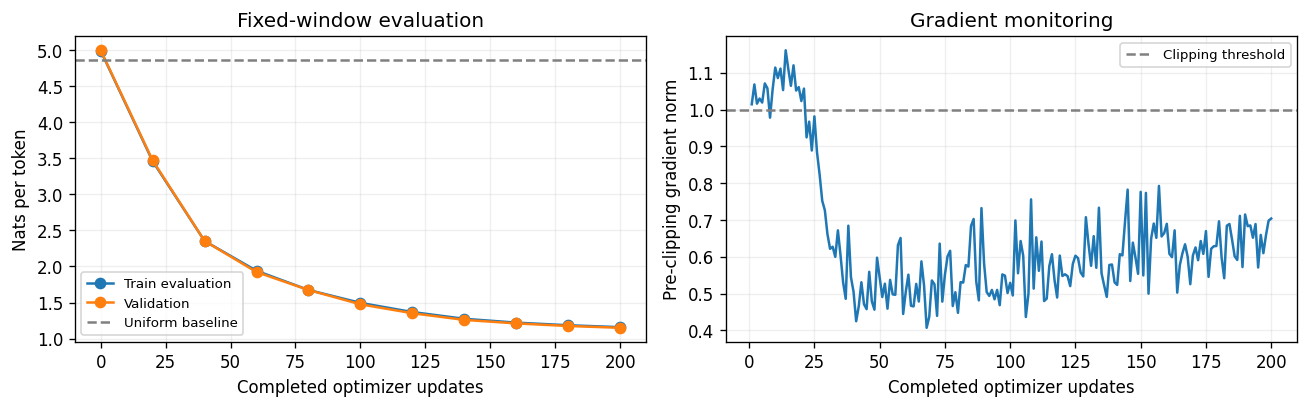

Validation loss: 4.996 -> 1.150
Validation perplexity: 147.77 -> 3.16
Saved files: ['config.json', 'data_manifest.json', 'final.pt', 'interrupted.pt', 'learning_rate.png', 'metrics.json', 'training_curves.png']


In [13]:
evaluations = history["evaluation"]
steps = [item["completed_updates"] for item in evaluations]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(steps, [item["train"]["loss"] for item in evaluations], marker="o", label="Train evaluation")
axes[0].plot(steps, [item["validation"]["loss"] for item in evaluations], marker="o", label="Validation")
axes[0].axhline(math.log(VOCAB_SIZE), linestyle="--", color="gray", label="Uniform baseline")
axes[0].set(xlabel="Completed optimizer updates", ylabel="Nats per token", title="Fixed-window evaluation")
axes[0].legend(fontsize=8)
axes[1].plot([r["update"] for r in history["updates"]], [r["grad_norm"] for r in history["updates"]])
axes[1].axhline(cfg.grad_clip, linestyle="--", color="gray", label="Clipping threshold")
axes[1].set(xlabel="Completed optimizer updates", ylabel="Pre-clipping gradient norm", title="Gradient monitoring")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RUN_DIR / "training_curves.png", dpi=140)
plt.show()
print(f"Validation loss: {initial_val['loss']:.3f} -> {final_val['loss']:.3f}")
print(f"Validation perplexity: {initial_val['perplexity']:.2f} -> {final_val['perplexity']:.2f}")
print("Saved files:", [path.name for path in sorted(RUN_DIR.iterdir())])


## 13. Transfer the workflow to the repository

The two repository trainers use different configuration names. Follow the command's own parser instead of mixing flag styles.

| Feature | `train_transformer.py` | `pretrain_base.py` |
|---|---|---|
| Configuration | Python config, presets, explicit CLI flags | `PretrainConfig`, JSON, field overrides |
| Update budget | `--steps` | `--train_steps` |
| Batch size | `--batch-size` | `--batch_size` |
| Accumulation | `--grad-accum` | `--grad_accum` |
| LR | Step decay | Warmup + cosine/WSD/linear |
| Precision | Optional bf16/fp16 on CUDA | Configured autocast, typically bf16 |
| Checkpoints | Periodic retention and `--resume latest` | Periodic save and `--resume PATH` |
| Scaling | One selected device | DDP via `torchrun` |

From the repository root, after installing its dependencies, the laptop path is:

```bash
python scripts/prepare_tiny_data.py
python scripts/train_transformer.py --preset tiny --arch modern --steps 200 --checkpoint-every 50 --keep-last 3
```

The first command downloads and prepares TinyStories and a tokenizer. Its output differs from this notebook's ASCII data. For an interrupted run, rerun with matching preset, architecture, total budget, and `--resume latest`. The budget is the total number of desired updates, not an additional count.

For the Pile path, prepare the correct HDF5 train/dev files from Step 1 before launching:

```bash
python scripts/train_transformer.py --preset 13m
python scripts/train_transformer.py --preset 77m --arch modern
python scripts/pretrain_base.py
```

The scalable trainer's data paths come from `configs/pretrain.json`. Verify model dimensions and memory budget before starting a larger configuration. The lab's `.pt` files use a teaching schema; use repository-produced checkpoints for repository generation scripts.


## 14. Mixed precision and activation checkpointing

**Autocast** chooses lower precision for supported operations while maintaining suitable precision for others. The main lab has an optional bf16 CUDA path. bf16 has a broad exponent range and normally does not require gradient scaling. FP16 often uses a `GradScaler` to reduce gradient underflow.

The FP16 operation order is:

```python
optimizer.zero_grad(set_to_none=True)
for microbatch in microbatches:
    with torch.autocast("cuda", dtype=torch.float16):
        _, loss = model(*microbatch)
    scaler.scale(loss / accumulation_steps).backward()
scaler.unscale_(optimizer)
torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
scaler.step(optimizer)
scaler.update()
```

A scaler can skip an optimizer update if gradients overflow. Track actual update semantics and save its state when resuming such a run.

**Activation checkpointing** recomputes selected forward operations during backward, reducing saved activation memory at extra compute cost. In the repository this is exposed on the classic model and through trainer options. It is distinct from saving a training checkpoint to disk.

```bash
python scripts/train_transformer.py --preset 13m --amp --grad-checkpointing --grad-accum 8
```

For FP32 AdamW, parameters, gradients, and two moment buffers alone use roughly 16 bytes per parameter. Activations, temporary tensors, allocator overhead, and attention intermediates add to this estimate. AMP does not automatically halve all training-state memory.


## 15. Distributed pretraining

With DDP, each worker owns a model replica. Workers compute local gradients and synchronize them so replicas apply consistent updates. With equal-sized batches, the global mean gradient averages across workers.

$$B_{effective}=B_{micro}\times K\times D,\qquad N_{tokens/update}=B_{micro}\times K\times D\times T.$$

For `B_micro=8`, `K=12`, `D=2`, and `T=128`, the effective batch contains 192 sequences and 24,576 target tokens per update.

```bash
torchrun --standalone --nproc_per_node=2 scripts/pretrain_base.py
```

The repository uses `no_sync()` for all but the last microbatch to reduce redundant communication. The forward and backward passes must both be inside that context. Its loader receives rank-dependent random seeds; independent shuffling does not guarantee perfectly disjoint examples across workers. Strict partitioning requires an appropriate distributed data sampler.

Only the main process writes the shared checkpoint. Evaluation metrics need cross-rank aggregation with the correct token weighting. The notebook's resume test verifies one process on its configured device; it does not verify a distributed restart.


## 16. Muon, WSD, and linear schedules

Step 3 also introduces Muon. For a 2D momentum matrix $M=U\Sigma V^T$, an idealized orthogonalized direction is $UV^T$ (semi-orthogonal for a rectangular full-rank matrix). The repository approximates that operation using five Newton–Schulz iterations. Finite iterations do not produce an exact polar factor.

Muon applies to selected hidden weight matrices. In the repository, embeddings, output weights, norms, and biases retain AdamW updates. This grouping and update scaling are part of the optimizer implementation, so replacing AdamW with an arbitrary orthogonalization function would omit important behavior.

WSD warms up, keeps the LR stable, then decays over the final portion of the run. Linear decay decreases LR at a constant rate after warmup. The following experiment plots these choices against the lab's cosine schedule.

```bash
python scripts/pretrain_base.py --arch modern --optimizer muon --lr_schedule wsd
python scripts/pretrain_base.py --lr_schedule linear --min_lr 0
```

**Exercise:** If you extend a cosine run's planned length after restoring a checkpoint, how does the LR at the next update change? Explain why the schedule budget is part of the experiment's state.


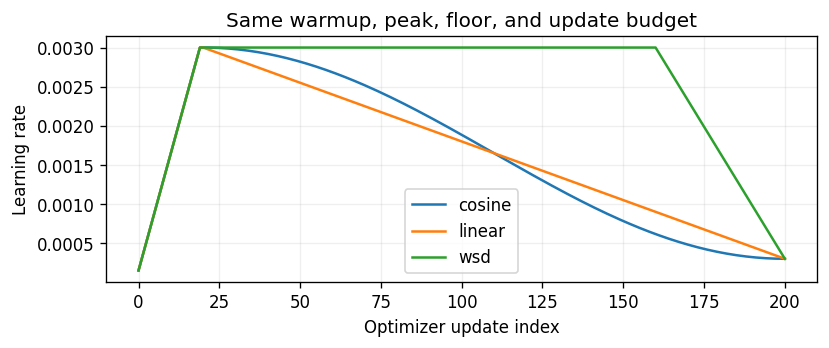

In [14]:
def comparison_schedule(kind, step):
    if step < cfg.warmup_updates:
        return cfg.peak_lr * (step + 1) / cfg.warmup_updates
    if step >= cfg.total_updates:
        return cfg.min_lr
    if kind == "cosine":
        return learning_rate(step)
    if kind == "linear":
        fraction = (step - cfg.warmup_updates) / (cfg.total_updates - cfg.warmup_updates)
    elif kind == "wsd":
        decay_start = max(cfg.warmup_updates, int(0.8 * cfg.total_updates))
        fraction = max(0.0, (step - decay_start) / (cfg.total_updates - decay_start))
    else:
        raise ValueError("Unknown schedule.")
    return cfg.peak_lr + fraction * (cfg.min_lr - cfg.peak_lr)

fig, ax = plt.subplots(figsize=(7, 3))
for kind in ("cosine", "linear", "wsd"):
    ax.plot(range(cfg.total_updates + 1), [comparison_schedule(kind, s) for s in range(cfg.total_updates + 1)], label=kind)
ax.set(xlabel="Optimizer update index", ylabel="Learning rate", title="Same warmup, peak, floor, and update budget")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RUN_DIR / "schedule_comparison.png", dpi=140)
plt.show()


## 17. Independent exercises

Complete these functions, then set `RUN_EXERCISE_CHECKS=True`. The reference training run above is independent of these starter functions.

1. **Cross-entropy:** use `logsumexp` and `gather` to compute mean next-token loss. Preserve autograd.
2. **Cosine LR:** reproduce the stated warmup and floor conventions. Assume `0 < warmup < total` and a nonnegative step.
3. **Token-weighted evaluation:** aggregate a sequence of `(mean_loss, token_count)` pairs. Reject an empty list or nonpositive token counts.

**Expected hand calculation:** losses 1.0 over 2 tokens and 3.0 over 6 tokens produce mean loss 2.5, rather than an unweighted batch mean of 2.0.


In [15]:
def student_cross_entropy(logits, targets):
    raise NotImplementedError

def student_cosine_lr(step, warmup, total, peak, floor):
    raise NotImplementedError

def student_weighted_loss(records):
    raise NotImplementedError

def check_exercises(cross_entropy_fn, schedule_fn, aggregate_fn):
    generator = torch.Generator().manual_seed(7)
    logits = torch.randn(2, 3, 5, generator=generator, requires_grad=True)
    targets = torch.tensor([[0, 1, 2], [3, 4, 0]])
    actual = cross_entropy_fn(logits, targets)
    expected = F.cross_entropy(logits.reshape(-1, 5), targets.reshape(-1))
    assert torch.allclose(actual, expected)
    actual_grad = torch.autograd.grad(actual, logits, retain_graph=True)[0]
    expected_grad = torch.autograd.grad(expected, logits)[0]
    assert torch.allclose(actual_grad, expected_grad, atol=1e-7)
    assert math.isclose(schedule_fn(0, 10, 100, 0.001, 0.0001), 0.0001)
    assert math.isclose(schedule_fn(10, 10, 100, 0.001, 0.0001), 0.001)
    assert math.isclose(schedule_fn(100, 10, 100, 0.001, 0.0001), 0.0001)
    assert math.isclose(schedule_fn(55, 10, 100, 0.001, 0.0001), 0.00055)
    assert math.isclose(aggregate_fn([(1.0, 2), (3.0, 6)]), 2.5)
    for invalid in ([], [(1.0, 0)]):
        try:
            aggregate_fn(invalid)
        except ValueError:
            continue
        raise AssertionError("Expected ValueError for empty/nonpositive-token input.")
    print("Exercise checks passed.")

RUN_EXERCISE_CHECKS = False
if RUN_EXERCISE_CHECKS:
    check_exercises(student_cross_entropy, student_cosine_lr, student_weighted_loss)
else:
    print("Complete the three starter functions, then enable the exercise checks.")


Complete the three starter functions, then enable the exercise checks.


## 18. Controlled experiments and assessment

Restart from the same seed and initial model for each experiment. Keep the data split and evaluation windows fixed. Record actual tokens processed in addition to update count.

| Experiment | Change | Prediction to write before running |
|---|---|---|
| Learning rate | Peak LR ×0.3 and ×3 | Which run learns faster or becomes less stable? |
| Accumulation | `(micro_batch=4, accum=2)` vs `(8,1)` | Does the same effective batch produce similar updates? |
| Schedule | Cosine vs WSD at equal token budget | Where should the loss curve change slope? |
| Data budget | Use fewer unique training documents | Does the train/validation gap widen? |
| Resume | Reload at update 100 | Does the verified next update match? |

For accumulation comparisons, use identical sampled windows and ordering, as in Section 7, to isolate numerical equivalence. Compare wall time separately. For a one-batch debugging experiment, repeatedly train on the same batch and confirm its loss falls; that experiment tests optimization plumbing rather than generalization.

**Submission rubric**
- Objective, baseline, and perplexity derivations: 15 points.
- Correct gradient accumulation and clipping order: 20 points.
- Training and token-weighted evaluation loop: 25 points.
- Checkpoint replay test and state explanation: 20 points.
- One controlled experiment with curves and interpretation: 20 points.

Submit your completed notebook, configuration, metrics, and a short paragraph explaining the validation trend. Treat generation quality as a separate evaluation in Lab 4.


## 19. Reference answers

Read these after attempting the exercises. The checks verify both cross-entropy values and gradients, schedule boundaries, and token weighting.


In [16]:
def reference_cross_entropy(logits, targets):
    log_normalizer = logits.logsumexp(dim=-1)
    target_logits = logits.gather(-1, targets.unsqueeze(-1)).squeeze(-1)
    return (log_normalizer - target_logits).mean()

def reference_cosine_lr(step, warmup, total, peak, floor):
    if step < warmup:
        return peak * (step + 1) / warmup
    if step >= total:
        return floor
    progress = (step - warmup) / (total - warmup)
    return floor + 0.5 * (peak - floor) * (1 + math.cos(math.pi * progress))

def reference_weighted_loss(records):
    if not records or any(count <= 0 for _, count in records):
        raise ValueError("Provide at least one record with positive token counts.")
    total_nll = sum(mean_loss * count for mean_loss, count in records)
    total_tokens = sum(count for _, count in records)
    return total_nll / total_tokens

check_exercises(reference_cross_entropy, reference_cosine_lr, reference_weighted_loss)


Exercise checks passed.


## 20. Completion checklist

- [ ] Explain why next-token cross-entropy supplies a pretraining objective.
- [ ] Distinguish a microbatch, optimizer update, and epoch.
- [ ] Derive effective batch size and predicted tokens per update.
- [ ] Pass the accumulated-gradient equivalence check.
- [ ] Interpret the train/validation curves and perplexity with the tokenizer held fixed.
- [ ] Pass checkpoint replay and explain every saved state field.
- [ ] Distinguish training checkpoints from activation checkpointing.
- [ ] Explain how AMP, DDP, Muon, and WSD extend the core loop.

**Verification record:** See the executed cell outputs for the CPU run and checks. The optional CUDA/bf16, FP16, DDP, and repository CLI recipes require separate validation on the corresponding environment. The small synthetic corpus supports a controlled training exercise.
